# 第 8 讲：线性模型、LDA 与 Logistic Regression

**PBL 交互式工作本 + 可复现实验（教师用完整版）**  
适用对象：生命科学专业、即将进入大四并准备交叉学科直博的学生

> **使用边界**：本 notebook 使用历史公开教学数据训练概念判断，不构成诊断、患者照护、临床部署或因果推断建议。

### 区域标识

- 🔵 **说明/概念区**：阅读问题、公式解释和任务要求，不在这里作答；
- 🟩 **运行/证据区**：运行代码并审计输出，原则上不修改代码；
- 🟨 **学生填写区**：正式学生版需要独立填写。本教师完整版已填入参考答案，答案用于说明论证深度，不是唯一标准措辞。

Notebook 元数据仍保留 `student-response`、`evidence`、`worksheet` 等标签，便于之后自动导出无答案学生版或按 Packet 分段发布。

**Driving question**  
对一组小样本、混合变量类型的心脏病数据，应如何在 LDA 与 logistic regression 之间作出可辩护的选择，并依据验证性能、概率校准、错误代价、模型假设和系数稳定性，判断哪些结论可以报告、哪些结论会失败？

## 如何使用这份 notebook

这不是“照着代码得到最高分”的 lab。你首先作出判断，随后逐包解锁证据，并在每一阶段记录：

1. **Claim**：你现在主张什么？
2. **Evidence**：哪些数字或图支持它？
3. **Reasoning**：证据为什么能支持主张？
4. **Boundary**：哪些结论仍不能说？

Packet A–D 应按顺序完成。教师可在 LMS 中分阶段发布；如果一次拿到整份 notebook，也请不要提前查看后续结果。

### 第一课堂：45 分钟

| 时间 | 个人任务 | 必须留下的证据 |
|---:|---|---|
| 0–7 min | 阅读病例触发，做初始投票 | 选择 + 一句话理由 |
| 7–15 min | 澄清目标、阳性类、错误代价 | 三个追问 |
| 15–24 min | 建立术语与数学对象对应关系 | 线性评分、概率、OR、LDA 假设 |
| 24–34 min | 完成 3W 与三种候选方案图 | 可证伪预测 |
| 34–41 min | 制定个人学习契约和证据卡 | 来源、核验标准 |
| 41–45 min | Exit ticket | 当前最关键的不确定性 |

### 完整 PBL 路线

**Section 1｜课堂一，45 分钟**  
只完成病例触发、初始判断、问题澄清、概念地图、3W、学习契约与第一次 exit ticket。第一项任务是作出判断，不是运行代码。

**Homework｜分阶段自学，建议 150 分钟**

| 模块 | 建议时间 | 学生任务 | 提交痕迹 |
|---|---:|---|---|
| Packet A | 15 min | 核对数据、变量类型与问题定义 | 初始立场与缺失证据清单 |
| Packet B | 30 min | 审计重复交叉验证结果 | 第一轮 CERB 记录 |
| Packet C | 50 min | 学习公式并审计假设、OR、共线性和阈值 | 概念检查与修订立场 |
| Packet D | 35 min | 打开锁定测试、校准与区间 | 最终决策矩阵 |
| Evidence Card + memo | 20 min | 独立核验一个自动化说法 | 来源卡与初稿 |

**Section 2｜课堂二，45 分钟**  
重新投票、同伴质询、教师短总结、修订个人决策备忘录与 exit ticket。具体时间表位于 notebook 末尾。

> notebook 为便于审核收录了全部 Packet；正式授课时可按标签拆分或由 LMS 逐段发布。

## 学习目标

完成本讲后，你应能：

- 用线性评分解释分类边界；
- 从 logit 与类条件高斯模型区分 logistic regression 和 LDA；
- 正确解释“每增加 1 单位/1 SD”的 odds ratio；
- 构建避免预处理泄漏的建模流程；
- 综合 AUC、sensitivity、specificity、Brier score、校准和不确定性评价模型；
- 根据漏诊/误报代价选择阈值，并写出有边界的结论。

### 参考阅读导航（不要求从头通读教材）

阅读任何教材、讲义或官方文档时，按下面四条线索摘录，而不是复制定义：

1. **共同结构**：线性评分、决策边界、特征尺度；
2. **Logistic**：sigmoid、logit、交叉熵、系数与 OR；
3. **LDA**：类条件高斯、共享协方差、类别先验、判别分数；
4. **证据边界**：区分预测与关联解释，查清 AUC、校准和阈值各回答什么问题。

遇到长推导时，先标出“输入、输出、假设、被优化或比较的量”；本讲不要求背矩阵求导。

In [1]:
# 🟩【运行/证据区】
# 运行并阅读输出；除非教师另有说明，学生不需要修改本单元。
from pathlib import Path
import json
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from IPython.display import display
from sklearn.base import clone
from sklearn.calibration import calibration_curve
from sklearn.compose import ColumnTransformer
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import (
    accuracy_score, average_precision_score, balanced_accuracy_score,
    brier_score_loss, confusion_matrix, log_loss, precision_score,
    recall_score, roc_auc_score, roc_curve
)
from sklearn.model_selection import (
    RepeatedStratifiedKFold, StratifiedKFold, cross_val_predict,
    train_test_split
)
from sklearn.naive_bayes import GaussianNB
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

warnings.filterwarnings("ignore", category=FutureWarning)
plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams["font.sans-serif"] = ["Microsoft YaHei", "SimHei", "Arial Unicode MS", "DejaVu Sans"]
plt.rcParams["axes.unicode_minus"] = False
pd.set_option("display.max_columns", 50)
pd.set_option("display.precision", 3)

RANDOM_STATE = 2026
SLUG = "linear-models-lda-logistic-regression"
candidates = [
    Path("../assets") / f"pbl-{SLUG}",
    Path("assets") / f"pbl-{SLUG}",
    Path.cwd().parent / "assets" / f"pbl-{SLUG}",
]
ASSET_DIR = next((p.resolve() for p in candidates if p.exists()), None)
if ASSET_DIR is None:
    raise FileNotFoundError("找不到本地 assets。请从第 8 讲目录或 notebook 子目录运行。")

print("Python:", __import__("sys").version.split()[0])
print("scikit-learn:", sklearn.__version__)
print("Assets:", ASSET_DIR)

Python: 3.14.6
scikit-learn: 1.9.0
Assets: D:\XMU\AI4BiomedicalDS\class2026\materials\8. Linear-models\assets\pbl-linear-models-lda-logistic-regression


# Packet A：先做判断，不要先跑模型

## 病例触发

一支研究团队希望使用 13 项检查结果，区分“心脏病存在”和“不存在”。

- 分析员 A：**选 LDA**，因为内部验证 AUC 略高，而且它能找到最佳线性区分方向。
- 分析员 B：**选 logistic regression**，因为“只有它能输出概率”，并可把最大的 OR 报告为独立致病因素。
- 项目负责人：所有模型一律使用 0.5 阈值。
- 数据说明：漏诊一例的代价按误报一例的 **5 倍**计算。

**你是否批准现有方案？** 先独立作答，不得以“都可以”回避；如果信息不足，要明确缺少哪类证据。

In [2]:
# 🟨【学生填写区｜教师参考答案】
# 正式学生版应由学生独立完成；本教师完整版给出一种可辩护答案，不是唯一措辞。
# 保留在看到任何模型结果前的判断
INITIAL_POSITION = "均不批准（信息不足）"
INITIAL_REASON = '''
现有陈述没有给出数据划分、未见数据表现、概率校准或错误类型，AUC 略高也未必超过抽样波动。
“只有 logistic regression 能输出概率”是错误的；OR 最大也不能自动变成独立致病因素。
在漏诊代价是误报 5 倍的设定下，固定使用 0.5 阈值尤其缺乏决策依据。
'''
THREE_QUESTIONS = [
    "训练、验证和锁定测试如何划分，预处理与阈值选择是否完全限制在开发数据内？",
    "两种模型在 AUC、校准、sensitivity、specificity 和 5×FN+FP 代价上是否有稳定差异？",
    "LDA 的高斯与共享协方差假设是否合理，logistic 系数与 OR 在重采样和共线性下是否稳定？",
]

In [3]:
# 🟩【运行/证据区】
# 运行并阅读输出；除非教师另有说明，学生不需要修改本单元。
data = pd.read_csv(ASSET_DIR / "statlog-heart.csv")
codebook = pd.read_csv(ASSET_DIR / "packet-a-data-dictionary.csv")
dataset_summary = pd.read_csv(ASSET_DIR / "dataset-summary.csv")

print("数据集摘要")
display(dataset_summary)
print("\n变量代码表")
display(codebook)
print("\n前 5 行（仅用于认识数据结构）")
display(data.head())

数据集摘要


,item,value,note
0,样本数,270,每行一名受试者
1,原始特征数,13,不含结局变量
2,结局,heart_disease_present,1=存在，0=不存在
3,阳性数,120,心脏病存在
4,阴性数,150,心脏病不存在
5,缺失单元格,0,UCI 页面亦标注无缺失
6,授权,CC BY 4.0,须保留署名和来源



变量代码表


,variable,type,working_meaning,unit_or_levels,modeling_note
0,age,连续,年龄,years,按 1 SD 标准化后进入模型
1,sex,二元,数据源编码的性别,1/0,仅作数据字段；不作生物学本质化解释
2,chest_pain,名义分类,胸痛类型,1–4,one-hot；1 为参照水平
3,resting_bp,连续,静息血压,mm Hg,按 1 SD 标准化
4,serum_cholesterol,连续,血清胆固醇,mg/dL,按 1 SD 标准化
5,fasting_blood_sugar,二元,空腹血糖是否大于 120 mg/dL,1/0,不标准化
6,resting_ecg,名义分类,静息心电图结果,0–2,one-hot；0 为参照水平
7,max_heart_rate,连续,最大心率,未注明,按 1 SD 标准化
8,exercise_angina,二元,运动诱发心绞痛,1/0,不标准化
9,oldpeak,连续,运动相对静息引起的 ST 段压低,未注明,按 1 SD 标准化



前 5 行（仅用于认识数据结构）


,age,sex,chest_pain,resting_bp,serum_cholesterol,fasting_blood_sugar,resting_ecg,max_heart_rate,exercise_angina,oldpeak,st_slope,major_vessels,thal,heart_disease_present
0,70,1,4,130,322,0,2,109,0,2.4,2,3,3,1
1,67,0,3,115,564,0,2,160,0,1.6,2,0,7,0
2,57,1,2,124,261,0,0,141,0,0.3,1,0,7,1
3,64,1,4,128,263,0,0,105,1,0.2,2,1,7,0
4,74,0,2,120,269,0,2,121,1,0.2,1,1,3,0


### Packet A 审计页

请在下面的代码单元中填写：

- **What we know**：已经知道且有证据支持的事实；
- **What we need to know**：作出模型选择前仍需知道什么；
- **What we will do**：用什么分析区分不同解释；
- 三个候选方案至少包括 LDA、logistic regression 和“证据不足/需修改流程”。

In [4]:
# 🟨【学生填写区｜教师参考答案】
# 正式学生版应由学生独立完成；本教师完整版给出一种可辩护答案，不是唯一措辞。
WHAT_WE_KNOW = [
    "任务是用 13 项混合类型特征预测二分类结局，且阳性类表示心脏病存在。",
    "漏诊代价被设为误报的 5 倍；现有三条模型主张都没有提供足够证据。",
]
WHAT_WE_NEED_TO_KNOW = [
    "两个模型在开发集重复交叉验证和锁定测试上的区分、校准与错误类型。",
    "LDA 的类条件分布及共享协方差假设受到多大挑战。",
    "logistic 系数、OR 与决策阈值对抽样波动、尺度和共线性是否稳定。",
]
WHAT_WE_WILL_DO = [
    "用无泄漏 pipeline 和重复分层交叉验证比较两种模型，并保留锁定测试集到 Packet D。",
    "检查偏态、变量类型和两类协方差差异，同时用 bootstrap 检查系数区间。",
    "只在开发集用 5×FN+FP 选择阈值，再一次性报告锁定测试表现及不确定区间。",
]

OPTION_MAP = {
    "LDA": {
        "predicted_evidence": "若共享协方差近似可接受，LDA 应在未见数据上保持良好区分与可接受校准。",
        "falsifying_evidence": "协方差差异大、概率严重失准，或其低代价阈值在锁定测试上明显劣于替代方案。",
        "consequence": "可把它作为当前协议下的候选预测器，但不能据此解释变量因果作用。",
    },
    "Logistic regression": {
        "predicted_evidence": "logit 线性近似若足够，模型应有稳定的未见数据表现，系数方向在重采样中基本一致。",
        "falsifying_evidence": "严重共线性导致系数任意分裂、校准差，或固定阈值下的临床错误代价较高。",
        "consequence": "可报告条件性关联和预测概率，但 OR 必须连同尺度、参照组、协变量与区间解释。",
    },
    "Revise / insufficient evidence": {
        "predicted_evidence": "两者差异小于不确定性，且小型内部数据不能支持部署或病因主张。",
        "falsifying_evidence": "预先设定协议下出现稳定、可重复且经外部验证的明显优势。",
        "consequence": "暂缓部署；补充验证、校准与目标人群证据，或降低主张强度。",
    },
}

LEARNING_CONTRACT = {
    "我必须弄清的问题": "LDA 与 logistic 的概率来源、线性边界、OR 和错误代价阈值怎样连接到同一个决策。",
    "准备核验的来源": "教材的 LDA/logistic 章节、scikit-learn 官方方法文档、Notebook 中冻结协议后的数值证据。",
    "完成标准": "能不用 API 名称解释公式，引用至少三项数值写出 CERB，并明确三条不可声称的结论。",
}
SECTION1_EXIT_TICKET = "目前最关键的不确定性是：在不查看锁定测试的前提下，哪个模型与阈值能在 5:1 错误代价下给出更可重复的权衡。"

## 数学支架：先看直觉，再读公式，最后回到决策

本节不假设你还记得所有微积分或概率论细节。每个公式分三层：

- **核心层（必须）**：知道每个符号代表什么、公式把什么量变成什么量；
- **理解层（必须）**：能用公式解释一个预测、一个 OR 或一条决策边界；
- **推导层（挑战）**：看懂 LDA 中为什么二次项会抵消。无需背诵，但要能沿步骤复述。

### 先恢复符号记忆

| 符号 | 本讲中的含义 | 在心脏病案例中的例子 |
|---|---|---|
| $Y$ | 结局标签 | $Y=1$ 表示心脏病存在 |
| $x_j$ | 第 $j$ 个特征的观测值 | 标准化后的年龄、某胸痛类型 |
| $\mathbf{x}$ | 一名受试者的全部特征组成的向量 | 13 项原始特征编码后的整行数据 |
| $\beta_j$ | 特征 $j$ 在 logistic 线性评分中的系数 | 年龄增加 1 SD 对 log-odds 的条件性变化 |
| $\beta_0$ | 截距；所有数值特征为 0 且分类变量处于参照水平时的基准 | 它不等同于总体患病率 |
| $z$ | 尚未压到 0–1 的线性评分 | 任意实数，正负都可以 |
| $p$ | 模型给出的阳性类概率 | $P(Y=1\mid\mathbf{x})$ |
| $\mu_k,\Sigma,\pi_k$ | LDA 中第 $k$ 类的均值、共享协方差和先验比例 | 两类受试者各自的特征中心、共同散布和比例 |

### 1. 共同起点：线性评分与决策边界

$$z=\beta_0+\mathbf{x}^T\boldsymbol{\beta}
  =\beta_0+\beta_1x_1+\cdots+\beta_px_p$$

右侧不是神秘的矩阵运算，而是“**每个特征乘一个权重，再相加**”。

- $\beta_j>0$：在其他输入固定时，$x_j$ 增大使评分 $z$ 增大；
- $\beta_j<0$：使评分减小；
- $|\beta_j|$ 的大小依赖单位。年龄按“年”或按“10 年”记录，系数数值会不同；
- 有相关特征时，“其他输入固定”可能是数据中很少出现的比较，所以系数要谨慎解释。

若以 $z=0$ 分类，则所有满足 $\beta_0+\mathbf{x}^T\boldsymbol{\beta}=0$ 的点组成一条直线（二维）或超平面（高维）。这就是“线性分类”的几何含义。

对 logistic regression，概率阈值 $t$ 对应的评分阈值为：

$$z_t=\log\frac{t}{1-t}$$

因而 $t=0.5$ 时 $z_t=0$；把概率阈值改为 0.2，并没有重新训练边界方向，而是在平行移动采取行动的位置。

### 2. Logistic regression：为什么要经过 sigmoid 和 logit？

线性评分 $z$ 可以从 $-\infty$ 到 $+\infty$，不能直接当概率。Sigmoid 把它平滑地压入 $(0,1)$：

$$p=P(Y=1\mid\mathbf{x})=\sigma(z)=\frac{1}{1+e^{-z}}$$

- $z=0\Rightarrow p=0.5$；
- $z$ 很大且为正，$p$ 接近 1；
- $z$ 很小且为负，$p$ 接近 0；
- sigmoid 单调，所以它改变“刻度”，不改变病例的排序。

Odds（优势）和 probability（概率）不是同一个量：

$$\operatorname{odds}=\frac{p}{1-p},\qquad
  \operatorname{logit}(p)=\log\frac{p}{1-p}=z$$

Logistic regression 的关键动作，就是让 **log-odds 成为特征的线性函数**。若其他变量固定，$x_j$ 增加 1 单位：

$$\Delta\operatorname{logit}(p)=\beta_j,
  \qquad \frac{\text{新 odds}}{\text{旧 odds}}=e^{\beta_j}=OR_j$$

例如 $\beta_j=0.7$，则 $OR=e^{0.7}\approx2.01$。这表示 odds 约乘 2，**不表示概率增加 70%，也不表示概率翻倍**；概率改变多少还取决于原来的 $p$。

**模型怎样找到 $\boldsymbol\beta$？** 对每名受试者，模型希望真实阳性时 $p_i$ 大、真实阴性时 $1-p_i$ 大。等价地，它最小化二元交叉熵：

$$\mathcal{L}(\boldsymbol\beta)
  =-\sum_i\left[y_i\log p_i+(1-y_i)\log(1-p_i)\right]$$

如果模型给一个真实阳性病例很小的 $p_i$，$-\log p_i$ 会很大，因此受到重罚。这里需要理解损失的方向，不要求手工求梯度。

,x_标准差单位,z,probability,odds,odds_ratio_vs_x0
0,0,-2.0,0.119,0.135,1.000
1,1,-1.3,0.214,0.273,2.014


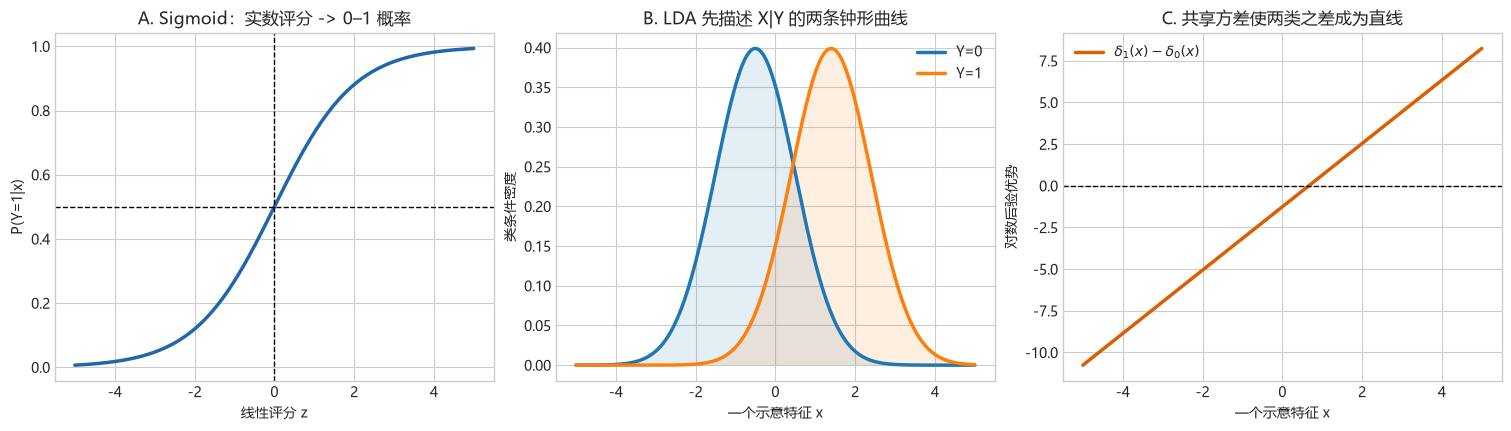

In [5]:
# 🟩【运行/证据区】
# 运行并阅读输出；除非教师另有说明，学生不需要修改本单元。
# 公式变成可见对象：修改 beta、截距、均值或先验，观察图形如何变化
sigmoid = lambda z: 1 / (1 + np.exp(-z))

beta0_example = -2.0
beta1_example = 0.7
example = pd.DataFrame({"x_标准差单位": [0, 1]})
example["z"] = beta0_example + beta1_example * example["x_标准差单位"]
example["probability"] = sigmoid(example["z"])
example["odds"] = example["probability"] / (1 - example["probability"])
example["odds_ratio_vs_x0"] = example["odds"] / example.loc[0, "odds"]
display(example.round(3))

grid = np.linspace(-5, 5, 500)
mu0, mu1, sigma = -0.5, 1.4, 1.0
pi0, pi1 = 0.6, 0.4
normal_pdf = lambda x, mu, sd: np.exp(-0.5 * ((x-mu)/sd)**2) / (sd*np.sqrt(2*np.pi))
density0 = normal_pdf(grid, mu0, sigma)
density1 = normal_pdf(grid, mu1, sigma)
lda_log_ratio = ((mu1-mu0)/(sigma**2))*grid - (mu1**2-mu0**2)/(2*sigma**2) + np.log(pi1/pi0)

fig, axes = plt.subplots(1, 3, figsize=(15, 4.2), constrained_layout=True)
axes[0].plot(grid, sigmoid(grid), color="#2166ac", lw=2.5)
axes[0].axvline(0, color="black", ls="--", lw=1)
axes[0].axhline(0.5, color="black", ls="--", lw=1)
axes[0].set(xlabel="线性评分 z", ylabel="P(Y=1|x)", title="A. Sigmoid：实数评分 -> 0–1 概率")

axes[1].plot(grid, density0, label="Y=0", lw=2.5)
axes[1].plot(grid, density1, label="Y=1", lw=2.5)
axes[1].fill_between(grid, density0, alpha=0.12)
axes[1].fill_between(grid, density1, alpha=0.12)
axes[1].set(xlabel="一个示意特征 x", ylabel="类条件密度", title="B. LDA 先描述 X|Y 的两条钟形曲线")
axes[1].legend()

axes[2].plot(grid, lda_log_ratio, color="#d95f02", lw=2.5,
             label=r"$\delta_1(x)-\delta_0(x)$")
axes[2].axhline(0, color="black", ls="--", lw=1)
axes[2].set(xlabel="一个示意特征 x", ylabel="对数后验优势", title="C. 共享方差使两类之差成为直线")
axes[2].legend()
fig.savefig(ASSET_DIR / "concept-logistic-lda-intuition.png", dpi=180, bbox_inches="tight")
plt.show()

### 3. LDA：为什么高斯模型最后会得到一条直线？

Logistic regression 从 $P(Y\mid X)$ 出发；LDA 反过来先描述“已知类别时，特征通常长什么样”：

$$\mathbf{X}\mid Y=k\sim\mathcal{N}(\boldsymbol\mu_k,\boldsymbol\Sigma),
  \qquad P(Y=k)=\pi_k$$

- $\boldsymbol\mu_k$：第 $k$ 类在特征空间中的中心；
- $\boldsymbol\Sigma$：特征的方差与特征之间的相关结构；LDA 假设各类别共享它；
- $\pi_k$：在观察特征前，第 $k$ 类的先验比例。

根据 Bayes rule，比起直接计算一个很长的概率乘积，我们比较每一类的对数判别分数。去掉对所有类别都相同的常数后：

$$\delta_k(\mathbf{x})
  =\mathbf{x}^T\boldsymbol\Sigma^{-1}\boldsymbol\mu_k
  -\frac12\boldsymbol\mu_k^T\boldsymbol\Sigma^{-1}\boldsymbol\mu_k
  +\log\pi_k$$

逐项解释：

1. $\mathbf{x}^T\Sigma^{-1}\mu_k$ 衡量样本与第 $k$ 类中心的匹配程度；
2. $\Sigma^{-1}$ 会降低高噪声方向的影响，并校正特征之间的相关；
3. 第二项校正不同类别中心本身的位置；
4. $\log\pi_k$ 把类别先验加入判断。改变患病率假设会移动决策位置。

**挑战层：二次项怎样消失？** 高斯对数密度中有

$$-\frac12(\mathbf{x}-\boldsymbol\mu_k)^T\Sigma^{-1}
  (\mathbf{x}-\boldsymbol\mu_k)$$

展开后包含 $-\frac12\mathbf{x}^T\Sigma^{-1}\mathbf{x}$。因为两类使用同一个 $\Sigma$，比较 $\delta_1-\delta_0$ 时，这个关于 $\mathbf{x}$ 的二次项完全抵消，剩下：

$$\delta_1(\mathbf{x})-\delta_0(\mathbf{x})
  =a+\mathbf{x}^T\underbrace{\Sigma^{-1}(\mu_1-\mu_0)}_{\mathbf{w}}$$

因此 LDA 的区分方向是 $\mathbf{w}=\Sigma^{-1}(\mu_1-\mu_0)$：不是只看两类均值差，而是用共同噪声与相关结构对均值差加权。若允许每一类有不同协方差，二次项不再抵消，就会得到 QDA 的二次边界。

### 4. 为什么 LDA 也能输出概率？两种模型究竟差在哪里？

对两类 LDA，Bayes rule 给出：

$$P(Y=1\mid\mathbf{x})
  =\frac{1}{1+\exp\{-[\delta_1(\mathbf{x})-\delta_0(\mathbf{x})]\}}$$

形式上它仍是一条 sigmoid 曲线。区别不在于“有没有概率”，而在于**概率背后的建模路线**：

| 方法 | 首先建模什么 | 线性从哪里来 | 主要代价或假设 | 本讲怎样审计 |
|---|---|---|---|---|
| Linear regression | $E(Y\mid X)$ | 连续均值直接等于线性评分 | 连续结局、同方差等；输出不受 0–1 限制 | 只作概念反例，不用于主分类任务 |
| Logistic regression | $P(Y=1\mid X)$ | log-odds 被设为线性 | logit 线性、观测独立、编码合理；系数可受共线性影响 | OR、bootstrap、校准、阈值 |
| LDA | $P(X\mid Y=k)$ 与 $P(Y=k)$ | 共享协方差使二次项抵消 | 类条件高斯、共享且可估计的协方差、先验合理 | 偏态、变量类型、协方差差异、校准 |

**回到病例**：如果 LDA 和 logistic regression 的 AUC 接近，选择就不能只依靠第三位小数；你还要问概率是否校准、阈值对应什么代价、模型假设是否合理，以及你究竟想做预测还是解释关联。

In [6]:
# 🟨【学生填写区｜教师参考答案】
# 正式学生版应由学生独立完成；本教师完整版给出一种可辩护答案，不是唯一措辞。
# 数学检查：允许计算器；评分依据是解释过程，不是只写数值
MATH_CHECK = {
    "1_z等于0时概率是多少_这对0点5阈值意味着什么": "sigmoid(0)=1/(1+e^0)=0.5。因此用 0.5 作概率阈值等价于在线性评分 z=0 处切分类别；它是数学对应关系，不代表 0.5 自动具有医学合理性。",
    "2_beta等于0点7时OR是多少_为什么不能说概率翻倍": "OR=e^0.7≈2.01，表示其他变量固定时，特征增加一个建模单位后 odds 约为原来的 2.01 倍。odds 不是 probability；概率变化还取决于起始概率，例如 0.1 的 odds 翻倍后概率约为 0.18，而不是 0.2。",
    "3_若阈值从0点5降到0点2_z阈值向哪个方向移动_漏诊和误报如何变化": "z 阈值从 logit(0.5)=0 降到 logit(0.2)=ln(0.2/0.8)≈-1.386。更多样本会被判为阳性，通常 FN 减少、sensitivity 上升，同时 FP 增加、specificity 下降。",
    "4_LDA中的Sigma逆矩阵在直觉上做了什么": "Sigma 记录各方向的方差及特征间相关；Sigma^{-1} 相当于按噪声和冗余重新加权距离：降低高方差方向的影响，并避免把强相关特征当成多份独立证据。",
    "5_共享协方差为何导致线性边界_若两类协方差不同会怎样": "比较两类高斯对数密度时，共享 Sigma 使共同的 x^T Sigma^{-1} x 二次项抵消，只剩常数加 x 的线性项；若两类各有 Sigma_k，二次项不能抵消，得到 QDA 式二次边界。",
    "6_LDA与logistic的概率分别依赖哪些假设": "Logistic 直接设定条件 log-odds 对特征线性，还依赖独立观测、合理编码和模型设定；LDA 先假设 X|Y 为类条件高斯、各类共享可估计协方差并给定先验，再经 Bayes rule 得到后验概率。两者的概率都需要校准审计。",
}

# 概念检查：用自己的话完成，不要逐句复制公式说明
CONCEPT_CHECK = {
    "两种模型为什么都能有线性边界": "Logistic 把 log-odds 直接写成特征的加权和；LDA 因各类共享协方差，在比较高斯对数后验时二次项抵消。两条路线都把分类条件化成 a+w^T x 与某个常数的比较。",
    "两种概率分别从哪里来": "Logistic 的概率来自线性评分经过 sigmoid；LDA 的概率来自类条件高斯密度、类别先验与 Bayes rule 组合得到的后验。",
    "LDA 最关键的共享假设": "各类别使用同一个协方差矩阵；这既决定线性边界，也决定相关方向如何被共同加权。",
    "为什么系数大小不能直接跨变量比较": "系数对应不同单位、标准化方式、分类参照水平和协变量集合；只有先统一尺度与编码，再考虑不确定性，数值大小才有有限的可比性。",
    "为什么 OR 不能自动解释成因果": "回归调整不能自动排除未测混杂、选择偏倚、反向因果和测量误差；因果解释还需要时间顺序、研究设计与额外识别假设。",
}

# 建模协议：先锁定测试集，再看证据

- 阳性类：`heart_disease_present = 1`；
- 80% 开发集，20% 锁定测试集；
- 连续变量只在每个训练折内标准化；
- 名义变量只在每个训练折内 one-hot；
- 模型选择、阈值选择都只使用开发集；
- Packet D 才允许查看锁定测试集。

这比“先在全数据上标准化，再切分”多写几行代码，但避免了信息泄漏。

In [7]:
# 🟩【运行/证据区】
# 运行并阅读输出；除非教师另有说明，学生不需要修改本单元。
TARGET = "heart_disease_present"
FEATURES = [c for c in data.columns if c != TARGET]
CONTINUOUS = ["age", "resting_bp", "serum_cholesterol", "max_heart_rate", "oldpeak", "major_vessels"]
BINARY = ["sex", "fasting_blood_sugar", "exercise_angina"]
CATEGORICAL = ["chest_pain", "resting_ecg", "st_slope", "thal"]
CATEGORY_LEVELS = [[1, 2, 3, 4], [0, 1, 2], [1, 2, 3], [3, 6, 7]]

X = data[FEATURES].copy()
y = data[TARGET].astype(int)
X_dev, X_test, y_dev, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE
)

def make_preprocessor(continuous=CONTINUOUS):
    return ColumnTransformer(
        [
            ("continuous", StandardScaler(), continuous),
            ("binary", "passthrough", BINARY),
            ("categorical", OneHotEncoder(
                categories=CATEGORY_LEVELS, drop="first",
                handle_unknown="ignore", sparse_output=False
            ), CATEGORICAL),
        ],
        remainder="drop",
        verbose_feature_names_out=False,
    )

def make_models():
    return {
        "Logistic regression": Pipeline([
            ("preprocess", make_preprocessor()),
            ("model", LogisticRegression(C=np.inf, solver="lbfgs", max_iter=5000,
                                         random_state=RANDOM_STATE)),
        ]),
        "LDA": Pipeline([
            ("preprocess", make_preprocessor()),
            ("model", LinearDiscriminantAnalysis(solver="svd")),
        ]),
        "Gaussian NB": Pipeline([
            ("preprocess", make_preprocessor()),
            ("model", GaussianNB()),
        ]),
        "Prevalence baseline": Pipeline([
            ("preprocess", make_preprocessor()),
            ("model", DummyClassifier(strategy="prior")),
        ]),
    }

models = make_models()
print(f"开发集: n={len(X_dev)}, 阳性={int(y_dev.sum())}; 锁定测试集: n={len(X_test)}, 阳性={int(y_test.sum())}")

开发集: n=216, 阳性=96; 锁定测试集: n=54, 阳性=24


# Packet B：两个线性模型真的有赢家吗？

我们首先只比较开发集证据。使用 5 折、重复 5 次的分层交叉验证；每一折都会重新拟合预处理和模型。

Gaussian NB 用于连接第 7 讲，prevalence baseline 用于防止把“看起来不差”误当成有效模型。

In [8]:
# 🟩【运行/证据区】
# 运行并阅读输出；除非教师另有说明，学生不需要修改本单元。
def metrics_at_threshold(y_true, probability, threshold=0.5):
    probability = np.asarray(probability)
    prediction = (probability >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, prediction, labels=[0, 1]).ravel()
    return {
        "roc_auc": roc_auc_score(y_true, probability),
        "pr_auc": average_precision_score(y_true, probability),
        "accuracy": accuracy_score(y_true, prediction),
        "balanced_accuracy": balanced_accuracy_score(y_true, prediction),
        "sensitivity": recall_score(y_true, prediction, pos_label=1),
        "specificity": recall_score(y_true, prediction, pos_label=0),
        "precision": precision_score(y_true, prediction, zero_division=0),
        "brier": brier_score_loss(y_true, probability),
        "log_loss": log_loss(y_true, probability, labels=[0, 1]),
        "tn": int(tn), "fp": int(fp), "fn": int(fn), "tp": int(tp),
        "weighted_error_cost": int(fp + 5 * fn),
        "threshold": float(threshold),
    }

cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=5, random_state=RANDOM_STATE)
cv_rows = []
for model_name, model in models.items():
    for fold, (train_idx, val_idx) in enumerate(cv.split(X_dev, y_dev), start=1):
        fitted = clone(model).fit(X_dev.iloc[train_idx], y_dev.iloc[train_idx])
        probability = fitted.predict_proba(X_dev.iloc[val_idx])[:, 1]
        cv_rows.append({
            "model": model_name,
            "fold": fold,
            **metrics_at_threshold(y_dev.iloc[val_idx], probability, 0.5),
        })

cv_results = pd.DataFrame(cv_rows)
cv_summary = cv_results.groupby("model").agg(
    auc_mean=("roc_auc", "mean"), auc_sd=("roc_auc", "std"),
    sensitivity_mean=("sensitivity", "mean"), sensitivity_sd=("sensitivity", "std"),
    specificity_mean=("specificity", "mean"), specificity_sd=("specificity", "std"),
    brier_mean=("brier", "mean"), brier_sd=("brier", "std"),
).reset_index()
cv_results.to_csv(ASSET_DIR / "packet-b-repeated-cv.csv", index=False)
cv_summary.to_csv(ASSET_DIR / "packet-b-model-comparison.csv", index=False)
display(cv_summary.round(3))

,model,auc_mean,auc_sd,sensitivity_mean,sensitivity_sd,specificity_mean,specificity_sd,brier_mean,brier_sd
0,Gaussian NB,0.861,0.038,0.743,0.177,0.722,0.210,0.233,0.078
1,LDA,0.910,0.030,0.777,0.083,0.877,0.057,0.125,0.027
2,Logistic regression,0.903,0.033,0.796,0.062,0.862,0.076,0.128,0.027
3,Prevalence baseline,0.500,0.000,0.000,0.000,1.000,0.000,0.247,0.001


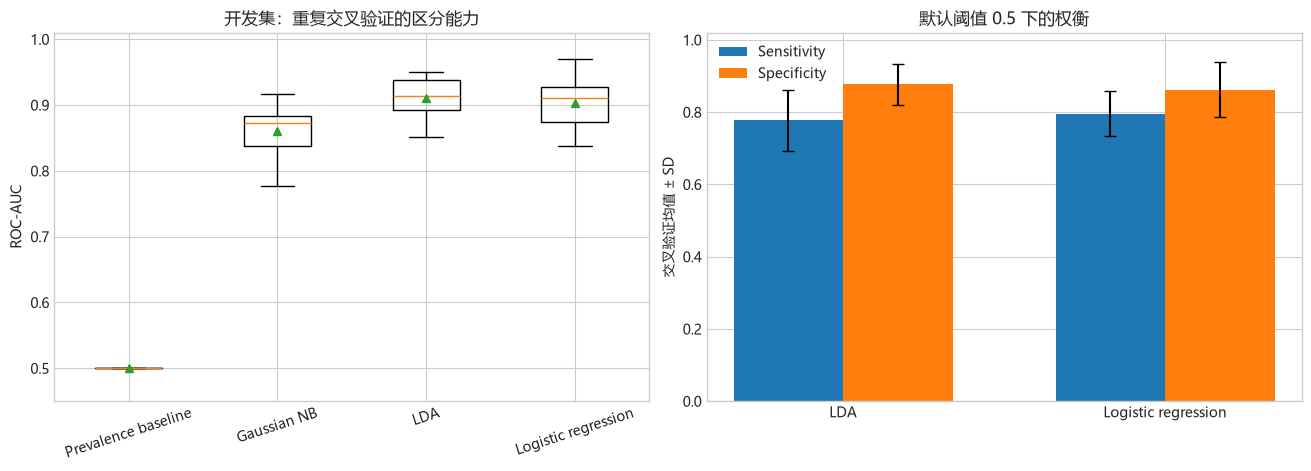

In [9]:
# 🟩【运行/证据区】
# 运行并阅读输出；除非教师另有说明，学生不需要修改本单元。
order = ["Prevalence baseline", "Gaussian NB", "LDA", "Logistic regression"]
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6), constrained_layout=True)
axes[0].boxplot(
    [cv_results.loc[cv_results.model == name, "roc_auc"] for name in order],
    tick_labels=order, showmeans=True
)
axes[0].set_ylim(0.45, 1.01)
axes[0].set_ylabel("ROC-AUC")
axes[0].set_title("开发集：重复交叉验证的区分能力")
axes[0].tick_params(axis="x", rotation=18)

positions = np.arange(2)
width = 0.34
linear_summary = cv_summary.set_index("model").loc[["LDA", "Logistic regression"]]
axes[1].bar(positions - width/2, linear_summary.sensitivity_mean, width,
            yerr=linear_summary.sensitivity_sd, label="Sensitivity", capsize=4)
axes[1].bar(positions + width/2, linear_summary.specificity_mean, width,
            yerr=linear_summary.specificity_sd, label="Specificity", capsize=4)
axes[1].set_xticks(positions, ["LDA", "Logistic regression"])
axes[1].set_ylim(0, 1.02)
axes[1].set_ylabel("交叉验证均值 ± SD")
axes[1].set_title("默认阈值 0.5 下的权衡")
axes[1].legend()
fig.savefig(ASSET_DIR / "packet-b-model-comparison.png", dpi=180, bbox_inches="tight")
plt.show()

In [10]:
# 🟨【学生填写区｜教师参考答案】
# 正式学生版应由学生独立完成；本教师完整版给出一种可辩护答案，不是唯一措辞。
PACKET_B_AUDIT = {
    "现在能得出什么": "在开发集重复交叉验证中，两种线性模型都明显优于 prevalence baseline，且性能接近。LDA 的平均 AUC 约 0.910、logistic 约 0.903；0.5 阈值下 logistic sensitivity 略高，而 LDA specificity 略高。",
    "仍不能得出什么": "不能宣布某模型在未来人群中更优，不能知道锁定测试表现，也不能由 AUC 判断概率是否校准、0.5 阈值是否符合 5:1 代价或 LDA 假设是否合理。",
    "哪一种解释被加强或削弱": "‘简单线性评分已能提取较强信号’被加强；‘AUC 第三位小数略高即可决定模型’被削弱。‘只有 logistic 能输出概率’已被公式和接口事实反驳。",
    "什么证据会改变你的选择": "开发集上的校准与代价阈值、LDA 假设审计、logistic 系数稳定性，以及冻结流程后的锁定测试和 bootstrap 区间。",
    "AUC 差异相对于折间波动是否足够大": "不足。均值差约 0.008，而两者折间 SD 约 0.030–0.033；这些重叠结果不支持仅凭平均 AUC 排名作强选择。",
}

# Packet C：假设、阈值与系数解释审计

Packet B 显示两个线性模型的区分能力接近。现在检查三个更难的问题：

1. LDA 的分布与共享协方差叙述是否可信？
2. Logistic 系数与 OR 是否稳定、是否能被当作独立危险因素？
3. 在漏诊代价更高时，0.5 阈值是否合理？

In [11]:
# 🟩【运行/证据区】
# 运行并阅读输出；除非教师另有说明，学生不需要修改本单元。
# 1) LDA 假设的描述性审计；不把单个正态性检验当作机械裁决器
standardized_continuous = pd.DataFrame(
    StandardScaler().fit_transform(X[CONTINUOUS]), columns=CONTINUOUS, index=X.index
)
covariance_0 = standardized_continuous[y == 0].cov().to_numpy()
covariance_1 = standardized_continuous[y == 1].cov().to_numpy()
relative_covariance_difference = np.linalg.norm(covariance_1 - covariance_0, ord="fro") / (
    (np.linalg.norm(covariance_1, ord="fro") + np.linalg.norm(covariance_0, ord="fro")) / 2
)

skew_table = X[CONTINUOUS].assign(target=y).groupby("target").skew().T.reset_index()
skew_table.columns = ["feature", "skew_absence", "skew_presence"]
skew_table["max_abs_skew"] = skew_table[["skew_absence", "skew_presence"]].abs().max(axis=1)
skew_table["relative_covariance_difference_all_continuous"] = relative_covariance_difference
skew_table.to_csv(ASSET_DIR / "packet-c-assumption-audit.csv", index=False)
print(f"两类标准化连续特征协方差矩阵的相对 Frobenius 差异: {relative_covariance_difference:.3f}")
print("注意：4 个名义分类变量与 3 个二元变量本身也不服从连续高斯分布。")
display(skew_table.sort_values("max_abs_skew", ascending=False).round(3))

两类标准化连续特征协方差矩阵的相对 Frobenius 差异: 0.559
注意：4 个名义分类变量与 3 个二元变量本身也不服从连续高斯分布。


,feature,skew_absence,skew_presence,max_abs_skew,relative_covariance_difference_all_continuous
5,major_vessels,2.483,0.435,2.483,0.559
2,serum_cholesterol,1.783,0.296,1.783,0.559
4,oldpeak,1.556,0.776,1.556,0.559
1,resting_bp,0.414,0.889,0.889,0.559
3,max_heart_rate,-0.677,-0.245,0.677,0.559
0,age,0.156,-0.546,0.546,0.559


In [12]:
# 🟩【运行/证据区】
# 运行并阅读输出；除非教师另有说明，学生不需要修改本单元。
# 2) Logistic 系数稳定性：在开发集内做非参数 bootstrap
logistic = models["Logistic regression"]
logistic_full = clone(logistic).fit(X_dev, y_dev)
feature_names = logistic_full.named_steps["preprocess"].get_feature_names_out()
reference_coefficients = logistic_full.named_steps["model"].coef_[0]

rng = np.random.default_rng(RANDOM_STATE)
boot_coefficients = []
for _ in range(300):
    idx = rng.integers(0, len(X_dev), len(X_dev))
    if np.unique(y_dev.iloc[idx]).size < 2:
        continue
    fitted = clone(logistic).fit(X_dev.iloc[idx], y_dev.iloc[idx])
    boot_coefficients.append(fitted.named_steps["model"].coef_[0])
boot_coefficients = np.vstack(boot_coefficients)

coefficient_rows = []
for j, feature in enumerate(feature_names):
    values = boot_coefficients[:, j]
    reference_sign = np.sign(reference_coefficients[j])
    coefficient_rows.append({
        "feature": feature,
        "coefficient_development": reference_coefficients[j],
        "odds_ratio": np.exp(np.clip(reference_coefficients[j], -20, 20)),
        "bootstrap_median": np.median(values),
        "bootstrap_q025": np.quantile(values, 0.025),
        "bootstrap_q975": np.quantile(values, 0.975),
        "sign_stability": np.mean(np.sign(values) == reference_sign),
    })
coefficient_table = pd.DataFrame(coefficient_rows).sort_values(
    "coefficient_development", key=np.abs, ascending=False
)
coefficient_table.to_csv(ASSET_DIR / "packet-c-logistic-coefficients.csv", index=False)
display(coefficient_table.round(3))
print("连续变量的 OR 对应增加 1 个训练集 SD；哑变量的 OR 相对于代码表中的参照水平。")

,feature,coefficient_development,odds_ratio,bootstrap_median,bootstrap_q025,bootstrap_q975,sign_stability
11,chest_pain_4,2.578,13.167,3.217,1.023,6.176,1.000
6,sex,1.826,6.208,2.150,0.478,4.670,0.993
17,thal_7,1.670,5.314,2.005,0.744,3.658,0.997
9,chest_pain_2,1.593,4.917,1.755,-1.544,4.905,0.863
14,st_slope_2,1.440,4.220,1.558,0.257,3.737,0.990
5,major_vessels,1.437,4.209,1.726,0.996,3.173,1.000
10,chest_pain_3,0.707,2.027,0.997,-0.926,3.608,0.797
4,oldpeak,0.604,1.829,0.790,-0.161,2.160,0.960
1,resting_bp,0.589,1.802,0.775,0.020,1.581,0.980
8,exercise_angina,0.572,1.772,0.646,-0.872,1.976,0.823


连续变量的 OR 对应增加 1 个训练集 SD；哑变量的 OR 相对于代码表中的参照水平。


In [13]:
# 🟩【运行/证据区】
# 运行并阅读输出；除非教师另有说明，学生不需要修改本单元。
# 可控共线性压力测试：人为加入 age 的近重复测量（不是原始数据字段）
X_dev_stress = X_dev.copy()
X_test_stress = X_test.copy()
stress_rng = np.random.default_rng(RANDOM_STATE)
X_dev_stress["age_near_duplicate"] = X_dev_stress["age"] + stress_rng.normal(0, 0.25, len(X_dev_stress))
X_test_stress["age_near_duplicate"] = X_test_stress["age"] + stress_rng.normal(0, 0.25, len(X_test_stress))

stress_continuous = CONTINUOUS + ["age_near_duplicate"]
stress_model = Pipeline([
    ("preprocess", make_preprocessor(stress_continuous)),
    ("model", LogisticRegression(C=np.inf, solver="lbfgs", max_iter=5000,
                                 random_state=RANDOM_STATE)),
]).fit(X_dev_stress, y_dev)
stress_names = stress_model.named_steps["preprocess"].get_feature_names_out()
stress_coef = pd.Series(stress_model.named_steps["model"].coef_[0], index=stress_names)
original_auc = roc_auc_score(y_test, logistic_full.predict_proba(X_test)[:, 1])
stress_auc = roc_auc_score(y_test, stress_model.predict_proba(X_test_stress)[:, 1])
collinearity_stress = pd.DataFrame({
    "quantity": ["原模型 age 系数", "压力测试 age 系数", "近重复 age 系数", "原模型测试 AUC", "压力测试测试 AUC"],
    "value": [
        pd.Series(reference_coefficients, index=feature_names)["age"],
        stress_coef["age"], stress_coef["age_near_duplicate"], original_auc, stress_auc
    ],
})
collinearity_stress.to_csv(ASSET_DIR / "packet-c-collinearity-stress-test.csv", index=False)
display(collinearity_stress.round(3))

,quantity,value
0,原模型 age 系数,-0.145
1,压力测试 age 系数,18.389
2,近重复 age 系数,-18.568
3,原模型测试 AUC,0.908
4,压力测试测试 AUC,0.917


In [14]:
# 🟩【运行/证据区】
# 运行并阅读输出；除非教师另有说明，学生不需要修改本单元。
# 3) 阈值只在开发集 OOF 概率上选择
def threshold_audit(y_true, probability):
    rows = []
    for threshold in np.round(np.linspace(0.05, 0.95, 181), 3):
        m = metrics_at_threshold(y_true, probability, threshold)
        rows.append({
            "threshold": threshold,
            "false_positive": m["fp"],
            "false_negative": m["fn"],
            "weighted_error_cost": m["weighted_error_cost"],
            "sensitivity": m["sensitivity"],
            "specificity": m["specificity"],
        })
    table = pd.DataFrame(rows)
    best = table.sort_values(
        ["weighted_error_cost", "sensitivity", "specificity"],
        ascending=[True, False, False]
    ).iloc[0]
    return float(best.threshold), table

oof_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
selected_thresholds = {}
threshold_tables = []
for model_name in ["Logistic regression", "LDA"]:
    oof_probability = cross_val_predict(
        models[model_name], X_dev, y_dev, cv=oof_cv, method="predict_proba"
    )[:, 1]
    selected_threshold, table = threshold_audit(y_dev, oof_probability)
    selected_thresholds[model_name] = selected_threshold
    table.insert(0, "model", model_name)
    threshold_tables.append(table)
threshold_results = pd.concat(threshold_tables, ignore_index=True)
threshold_results.to_csv(ASSET_DIR / "packet-c-threshold-audit.csv", index=False)
display(pd.DataFrame({"model": selected_thresholds.keys(), "selected_threshold": selected_thresholds.values()}))

,model,selected_threshold
0,Logistic regression,0.14
1,LDA,0.11


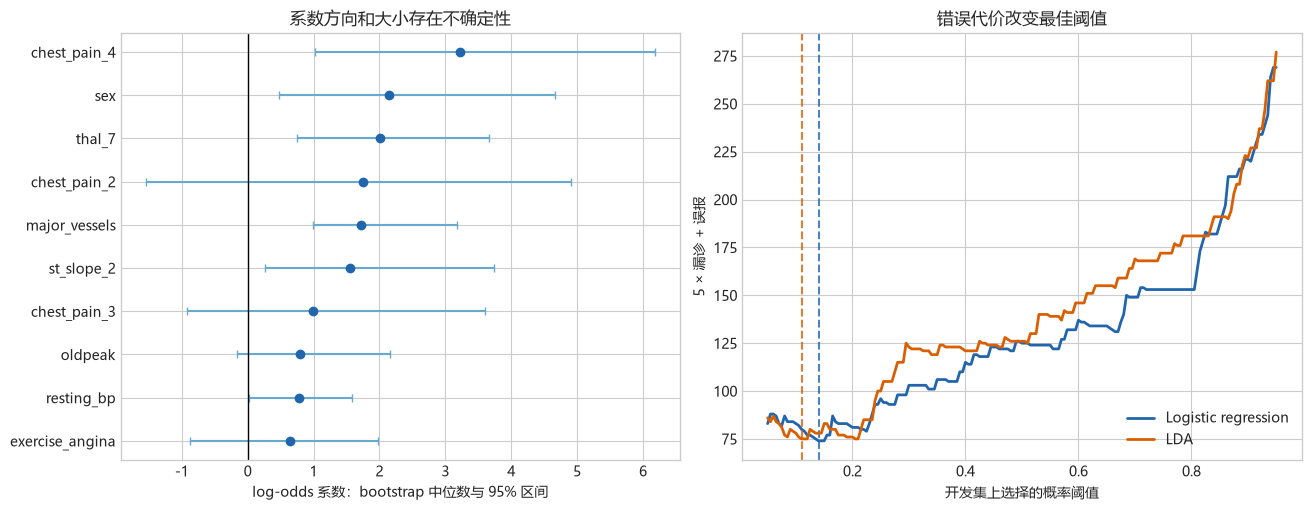

In [15]:
# 🟩【运行/证据区】
# 运行并阅读输出；除非教师另有说明，学生不需要修改本单元。
fig, axes = plt.subplots(1, 2, figsize=(13, 5), constrained_layout=True)
plot_coefficients = coefficient_table.head(10).sort_values("bootstrap_median")
xerr = np.vstack([
    plot_coefficients.bootstrap_median - plot_coefficients.bootstrap_q025,
    plot_coefficients.bootstrap_q975 - plot_coefficients.bootstrap_median,
])
axes[0].errorbar(
    plot_coefficients.bootstrap_median, np.arange(len(plot_coefficients)),
    xerr=xerr, fmt="o", capsize=3, color="#2166ac", ecolor="#67a9cf"
)
axes[0].axvline(0, color="black", lw=1)
axes[0].set_yticks(np.arange(len(plot_coefficients)), plot_coefficients.feature)
axes[0].set_xlabel("log-odds 系数：bootstrap 中位数与 95% 区间")
axes[0].set_title("系数方向和大小存在不确定性")

colors = {"Logistic regression": "#2166ac", "LDA": "#d95f02"}
for model_name, color in colors.items():
    part = threshold_results[threshold_results.model == model_name]
    axes[1].plot(part.threshold, part.weighted_error_cost, lw=2,
                 label=model_name, color=color)
    axes[1].axvline(selected_thresholds[model_name], ls="--", color=color, alpha=0.8)
axes[1].set_xlabel("开发集上选择的概率阈值")
axes[1].set_ylabel("5 × 漏诊 + 误报")
axes[1].set_title("错误代价改变最佳阈值")
axes[1].legend()
fig.savefig(ASSET_DIR / "packet-c-coefficients-and-thresholds.png", dpi=180, bbox_inches="tight")
plt.show()

In [16]:
# 🟨【学生填写区｜教师参考答案】
# 正式学生版应由学生独立完成；本教师完整版给出一种可辩护答案，不是唯一措辞。
PACKET_C_AUDIT = {
    "现在能得出什么": "5×FN+FP 的目标使开发集所选阈值显著低于 0.5（logistic 约 0.14，LDA 约 0.11）。LDA 假设只是近似，部分 logistic 系数也有很宽或跨 0 的 bootstrap 区间。",
    "仍不能得出什么": "尚不能知道这些阈值在锁定测试上的代价，也不能把描述性假设偏离机械地变成‘LDA 一定无效’，或把任何一个 OR 称为可重复的因果效应。",
    "LDA 假设受到了什么挑战": "输入同时含连续、二元和分类变量，并非理想的连续多元高斯；serum_cholesterol、oldpeak、major_vessels 等在至少一类中明显偏态，两类连续变量协方差的相对 Frobenius 差约 0.559。",
    "选一个 OR 并给出完整条件性解释": "开发集 logistic 中 major_vessels 的系数约 1.437，OR=e^1.437≈4.21：在当前预处理、其他入模变量固定且连续变量按开发集标准化的条件下，该变量增加 1 SD 与心脏病存在的 odds 约 4.21 倍相关。它不是概率倍数，也不是因果效应；bootstrap 区间与外部验证仍应报告。",
    "共线性压力测试改变了系数还是预测，为什么": "加入 age 的近重复变量后，age 系数从约 -0.145 变为 18.389，重复变量系数约 -18.568，但测试 AUC 仅从 0.908 变到 0.917。高度相关变量可用许多相互抵消的权重产生近似线性评分，因此预测相近而单个系数极不稳定。",
    "为什么不能在锁定测试集上重新找阈值": "一旦用测试标签选择阈值，测试集就参与了模型选择，报告的性能会对这批样本乐观且不再代表独立泛化检验。阈值必须在开发数据中冻结。",
}

# Packet D：一次性打开锁定测试集

现在才允许拟合全部开发数据并查看 54 例测试集。注意：这只是一次小型内部测试，不是外部验证。

我们将同时报告：ROC-AUC、PR-AUC、sensitivity、specificity、Brier score、混淆矩阵和 bootstrap 区间。阈值沿用 Packet C 的开发集选择，不能根据测试结果回调。

In [17]:
# 🟩【运行/证据区】
# 运行并阅读输出；除非教师另有说明，学生不需要修改本单元。
fitted_models = {}
test_probabilities = {}
locked_rows = []
for model_name, model in models.items():
    fitted = clone(model).fit(X_dev, y_dev)
    probability = fitted.predict_proba(X_test)[:, 1]
    threshold = selected_thresholds.get(model_name, 0.5)
    fitted_models[model_name] = fitted
    test_probabilities[model_name] = probability
    locked_rows.append({
        "model": model_name,
        **metrics_at_threshold(y_test, probability, threshold),
    })
locked_test = pd.DataFrame(locked_rows)
locked_test.to_csv(ASSET_DIR / "packet-d-locked-test.csv", index=False)
display(locked_test.round(3))

,model,roc_auc,pr_auc,accuracy,balanced_accuracy,sensitivity,specificity,precision,brier,log_loss,tn,fp,fn,tp,weighted_error_cost,threshold
0,Logistic regression,0.908,0.896,0.704,0.729,0.958,0.500,0.605,0.111,0.429,15,15,1,23,20,0.14
1,LDA,0.906,0.896,0.759,0.779,0.958,0.600,0.657,0.116,0.438,18,12,1,23,17,0.11
2,Gaussian NB,0.900,0.894,0.852,0.850,0.833,0.867,0.833,0.130,0.859,26,4,4,20,24,0.50
3,Prevalence baseline,0.500,0.444,0.556,0.500,0.000,1.000,0.000,0.247,0.687,30,0,24,0,120,0.50


In [18]:
# 🟩【运行/证据区】
# 运行并阅读输出；除非教师另有说明，学生不需要修改本单元。
# 锁定测试预测的分层 bootstrap；不重新拟合模型
rng = np.random.default_rng(RANDOM_STATE)
y_test_array = y_test.to_numpy()
idx0 = np.flatnonzero(y_test_array == 0)
idx1 = np.flatnonzero(y_test_array == 1)
bootstrap_rows = []
for _ in range(1000):
    sample_idx = np.concatenate([
        rng.choice(idx0, len(idx0), replace=True),
        rng.choice(idx1, len(idx1), replace=True),
    ])
    rng.shuffle(sample_idx)
    y_boot = y_test_array[sample_idx]
    for model_name in ["Logistic regression", "LDA"]:
        m = metrics_at_threshold(
            y_boot, test_probabilities[model_name][sample_idx],
            selected_thresholds[model_name]
        )
        for metric in ["roc_auc", "pr_auc", "sensitivity", "specificity", "brier"]:
            bootstrap_rows.append({"model": model_name, "metric": metric, "value": m[metric]})

bootstrap_distribution = pd.DataFrame(bootstrap_rows)
bootstrap_ci = bootstrap_distribution.groupby(["model", "metric"])["value"].agg(
    estimate="median",
    ci_low=lambda s: s.quantile(0.025),
    ci_high=lambda s: s.quantile(0.975),
).reset_index()
bootstrap_ci.to_csv(ASSET_DIR / "packet-d-bootstrap-ci.csv", index=False)
display(bootstrap_ci.round(3))

,model,metric,estimate,ci_low,ci_high
0,LDA,brier,0.115,0.053,0.195
1,LDA,pr_auc,0.902,0.799,0.974
2,LDA,roc_auc,0.910,0.806,0.978
3,LDA,sensitivity,0.958,0.875,1.000
4,LDA,specificity,0.600,0.433,0.767
5,Logistic regression,brier,0.111,0.054,0.184
6,Logistic regression,pr_auc,0.903,0.796,0.977
7,Logistic regression,roc_auc,0.911,0.806,0.979
8,Logistic regression,sensitivity,0.958,0.875,1.000
9,Logistic regression,specificity,0.500,0.333,0.667


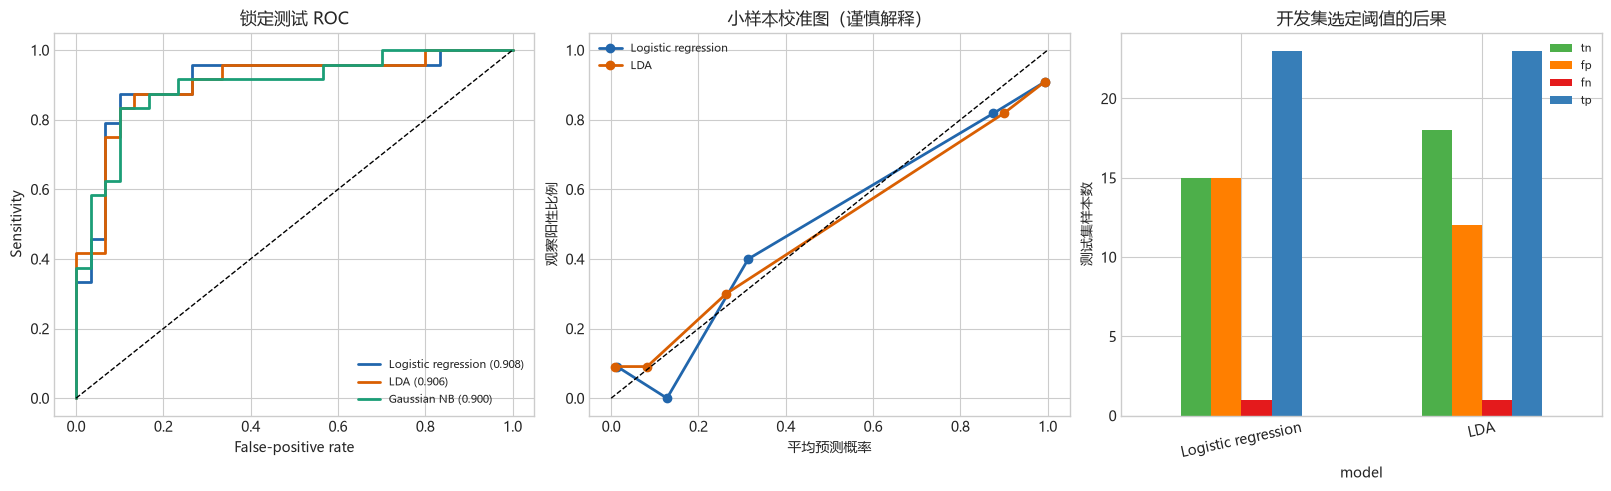

In [19]:
# 🟩【运行/证据区】
# 运行并阅读输出；除非教师另有说明，学生不需要修改本单元。
fig, axes = plt.subplots(1, 3, figsize=(16, 4.8), constrained_layout=True)
colors = {"Logistic regression": "#2166ac", "LDA": "#d95f02", "Gaussian NB": "#1b9e77"}
for model_name in ["Logistic regression", "LDA", "Gaussian NB"]:
    fpr, tpr, _ = roc_curve(y_test, test_probabilities[model_name])
    auc = roc_auc_score(y_test, test_probabilities[model_name])
    axes[0].plot(fpr, tpr, lw=2, label=f"{model_name} ({auc:.3f})", color=colors[model_name])
axes[0].plot([0, 1], [0, 1], "k--", lw=1)
axes[0].set_xlabel("False-positive rate")
axes[0].set_ylabel("Sensitivity")
axes[0].set_title("锁定测试 ROC")
axes[0].legend(fontsize=8)

for model_name in ["Logistic regression", "LDA"]:
    observed, predicted = calibration_curve(
        y_test, test_probabilities[model_name], n_bins=5, strategy="quantile"
    )
    axes[1].plot(predicted, observed, marker="o", lw=2,
                 label=model_name, color=colors[model_name])
axes[1].plot([0, 1], [0, 1], "k--", lw=1)
axes[1].set_xlabel("平均预测概率")
axes[1].set_ylabel("观察阳性比例")
axes[1].set_title("小样本校准图（谨慎解释）")
axes[1].legend(fontsize=8)

confusion = locked_test.set_index("model").loc[["Logistic regression", "LDA"], ["tn", "fp", "fn", "tp"]]
confusion.plot(kind="bar", ax=axes[2], color=["#4daf4a", "#ff7f00", "#e41a1c", "#377eb8"])
axes[2].set_ylabel("测试集样本数")
axes[2].set_title("开发集选定阈值的后果")
axes[2].tick_params(axis="x", rotation=12)
axes[2].legend(fontsize=8)
fig.savefig(ASSET_DIR / "packet-d-roc-calibration-confusion.png", dpi=180, bbox_inches="tight")
plt.show()

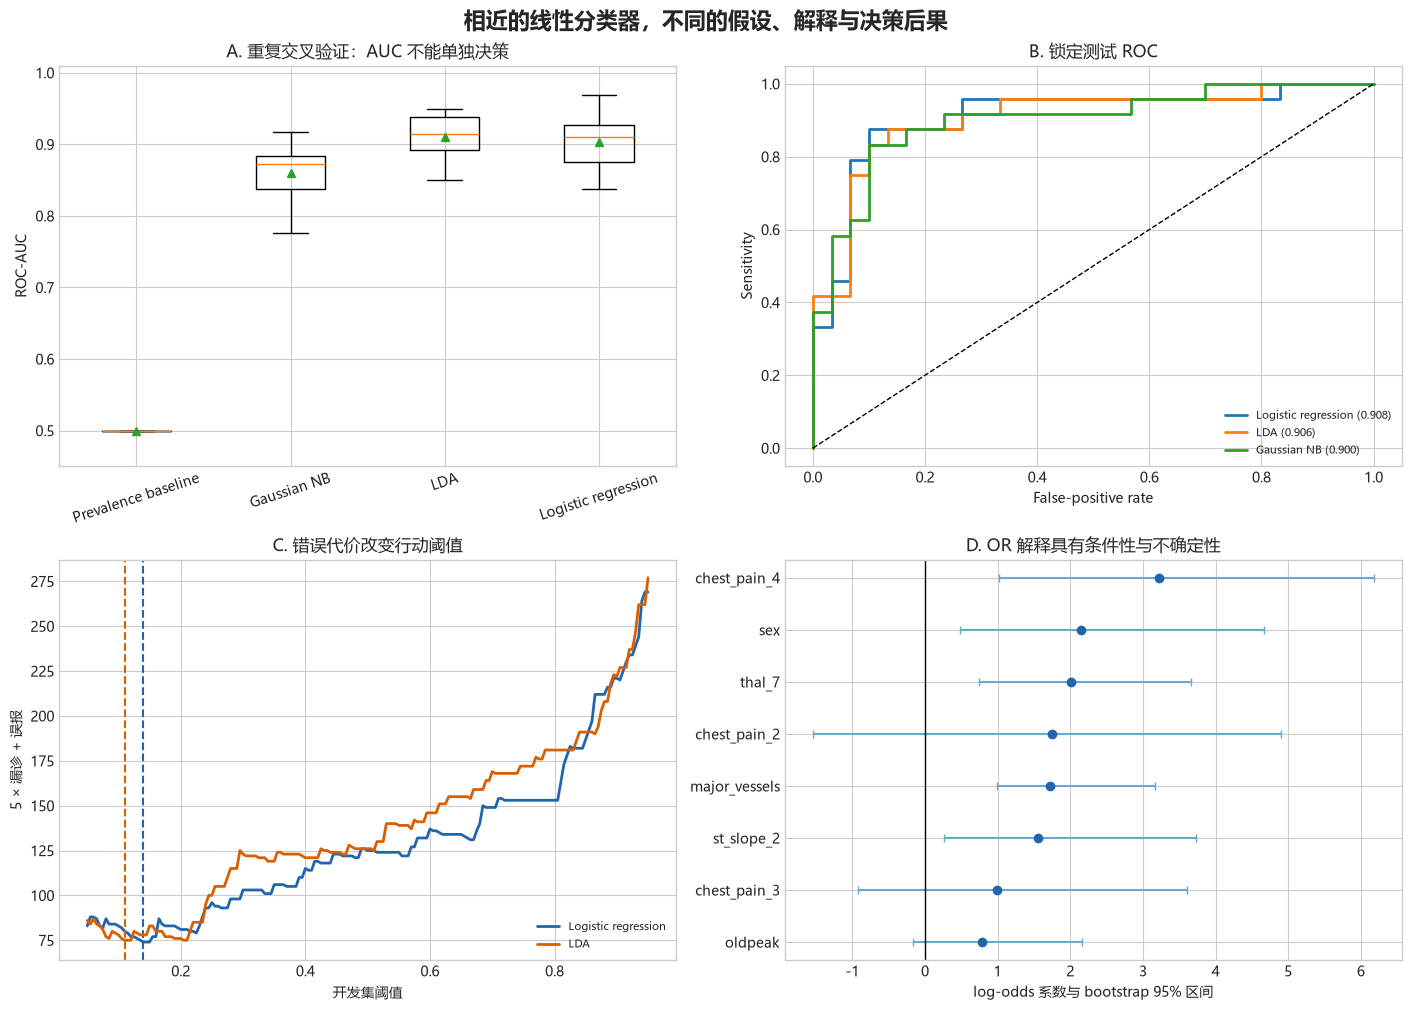

In [20]:
# 🟩【运行/证据区】
# 运行并阅读输出；除非教师另有说明，学生不需要修改本单元。
# 综合主结果图：用于复核证据链，不是“冠军榜”
fig, axes = plt.subplots(2, 2, figsize=(14, 10), constrained_layout=True)
order = ["Prevalence baseline", "Gaussian NB", "LDA", "Logistic regression"]
axes[0, 0].boxplot(
    [cv_results.loc[cv_results.model == name, "roc_auc"] for name in order],
    tick_labels=order, showmeans=True
)
axes[0, 0].set_ylim(0.45, 1.01)
axes[0, 0].set_ylabel("ROC-AUC")
axes[0, 0].set_title("A. 重复交叉验证：AUC 不能单独决策")
axes[0, 0].tick_params(axis="x", rotation=18)

for model_name in ["Logistic regression", "LDA", "Gaussian NB"]:
    fpr, tpr, _ = roc_curve(y_test, test_probabilities[model_name])
    auc = roc_auc_score(y_test, test_probabilities[model_name])
    axes[0, 1].plot(fpr, tpr, lw=2, label=f"{model_name} ({auc:.3f})")
axes[0, 1].plot([0, 1], [0, 1], "k--", lw=1)
axes[0, 1].set_xlabel("False-positive rate")
axes[0, 1].set_ylabel("Sensitivity")
axes[0, 1].set_title("B. 锁定测试 ROC")
axes[0, 1].legend(fontsize=8)

for model_name, color in colors.items():
    if model_name not in selected_thresholds:
        continue
    part = threshold_results[threshold_results.model == model_name]
    axes[1, 0].plot(part.threshold, part.weighted_error_cost,
                    label=model_name, color=color, lw=2)
    axes[1, 0].axvline(selected_thresholds[model_name], color=color, ls="--")
axes[1, 0].set_xlabel("开发集阈值")
axes[1, 0].set_ylabel("5 × 漏诊 + 误报")
axes[1, 0].set_title("C. 错误代价改变行动阈值")
axes[1, 0].legend(fontsize=8)

plot_coefficients = coefficient_table.head(8).sort_values("bootstrap_median")
xerr = np.vstack([
    plot_coefficients.bootstrap_median - plot_coefficients.bootstrap_q025,
    plot_coefficients.bootstrap_q975 - plot_coefficients.bootstrap_median,
])
axes[1, 1].errorbar(
    plot_coefficients.bootstrap_median, np.arange(len(plot_coefficients)),
    xerr=xerr, fmt="o", capsize=3, color="#2166ac", ecolor="#67a9cf"
)
axes[1, 1].axvline(0, color="black", lw=1)
axes[1, 1].set_yticks(np.arange(len(plot_coefficients)), plot_coefficients.feature)
axes[1, 1].set_xlabel("log-odds 系数与 bootstrap 95% 区间")
axes[1, 1].set_title("D. OR 解释具有条件性与不确定性")

fig.suptitle("相近的线性分类器，不同的假设、解释与决策后果", fontsize=16, fontweight="bold")
fig.savefig(ASSET_DIR / "main-result-linear-models.png", dpi=180, bbox_inches="tight")
plt.show()

## Packet D 最终审计

回答时不得只写“LDA/Logistic 更好”。必须说明：研究目标、证据、阈值、假设和边界。

**概念辨析**

| 概念 A | 概念 B | 必须说明的区别 |
|---|---|---|
| Linear regression | Logistic regression | 结局类型、链接函数、预测范围、损失 |
| LDA | Logistic regression | 生成式/判别式、分布假设、概率来源 |
| Probability | Odds | $p$ 与 $p/(1-p)$ |
| Coefficient | Odds ratio | $\beta$ 与 $e^\beta$；尺度和参照水平 |
| Association | Causation | 调整变量与研究设计不能被模型自动补足 |
| AUC | Threshold performance | 排序能力不决定具体 sensitivity/specificity |

In [21]:
# 🟨【学生填写区｜教师参考答案】
# 正式学生版应由学生独立完成；本教师完整版给出一种可辩护答案，不是唯一措辞。
FINAL_DECISION_MEMO = {
    "Claim_选择什么模型或为何暂不定夺": "若任务仅限于本教学数据的内部预测比较，我暂选 LDA 并沿用开发集阈值 0.11；但我不批准把 LDA 或 logistic 直接部署，也不批准把系数写成致病结论。",
    "Evidence_至少引用三个具体结果": "(1) 重复交叉验证 AUC：LDA 约 0.910±0.030，logistic 约 0.903±0.033，差异很小；(2) 锁定测试中两者 sensitivity 都为 0.958，LDA specificity=0.600、代价=17，logistic specificity=0.500、代价=20；(3) 两者锁定测试 AUC 约 0.906 与 0.908，bootstrap 95% 区间高度重叠；(4) LDA 连续变量协方差相对差约 0.559，且数据含非高斯的离散变量。",
    "Reasoning_把证据连接到研究目的和错误代价": "目标把漏诊计为误报的 5 倍，所以先要求高 sensitivity，再在相同漏诊数下减少 FP。冻结阈值后，LDA 在 54 例锁定测试中与 logistic 同为 1 个 FN，但少 3 个 FP，因此本次协议下代价稍低；不过差异只有 3 个病例且区间重叠，只能形成暂定选择。",
    "Boundary_至少写三条不能声称的结论": "不能声称 LDA 普遍优于 logistic；不能把内部测试表现当成外部临床有效性或患者获益；不能把 OR 当作因果效应或变量重要性的唯一排序；不能保证换医院、患病率或测量流程后仍校准；不能根据 54 例测试精确估计总体 sensitivity/specificity。",
    "Threshold_选择及其代价依据": "使用开发集 OOF 预测最小化 5×FN+FP，冻结 LDA 阈值约 0.11。不能因锁定测试结果再回调；实际应用还需用真实临床效用、资源约束和目标人群患病率重新预设并验证。",
    "OR_interpretation_选一项变量完整解释": "major_vessels 的开发集系数约 1.437、OR≈4.21：在该样本、当前编码与其他入模变量固定时，标准化后的 major_vessels 增加 1 SD 与结局 odds 约增加到 4.21 倍相关。该数值不是概率倍数，不代表干预该变量会改变风险，也需要区间和外部复现。",
}

REVISED_POSITION = "从‘均不批准、信息不足’修订为：仅在冻结的教学分析协议内暂选 LDA；对临床部署和病因主张仍不批准。"
WHAT_CHANGED_MY_MIND = "真正改变判断的不是 AUC 第三位小数，而是开发集按 5:1 代价冻结阈值后，锁定测试中两者同为 1 个 FN，LDA 少 3 个 FP；同时区间重叠迫使我降低结论强度。"
REMAINING_UNCERTAINTY = "最大的剩余不确定性是外部人群中的校准与临床净获益，以及标签质量、患病率变化和测量流程改变是否会破坏当前权衡。"

In [22]:
# 🟨【学生填写区｜教师参考答案】
# 正式学生版应由学生独立完成；本教师完整版给出一种可辩护答案，不是唯一措辞。
# 最终决策矩阵：不要只填模型名，每一列都必须有证据
DECISION_MATRIX = {
    "LDA": {
        "适用理由或假设": "类条件分布与共享协方差是可用近似；样本量足以估计稳定的线性判别方向；任务重视预测。",
        "本数据支持证据": "CV AUC≈0.910；冻结阈值的锁定测试 sensitivity=0.958、specificity=0.600、加权代价=17，为两种线性模型中较低。",
        "反对或限制证据": "混合变量不满足理想连续高斯；若干变量偏态；两类协方差相对差≈0.559；小测试集区间较宽。",
        "验证检查": "按类检查分布与协方差、概率校准、先验敏感性、重采样区间、外部验证；高维时比较 shrinkage LDA。",
        "何时停止使用或降低主张": "协方差估计不稳定、外部校准或代价恶化、先验变化导致阈值失效时；即使预测尚可也不作因果解释。",
    },
    "Logistic regression": {
        "适用理由或假设": "直接建模条件概率的 log-odds，适合二分类；编码和 logit 线性近似合理时，可给出有条件的 OR。",
        "本数据支持证据": "CV AUC≈0.903；锁定测试 AUC≈0.908、Brier≈0.111、sensitivity=0.958，区分能力与 LDA 接近。",
        "反对或限制证据": "阈值 0.14 时 specificity=0.500、代价=20；多个 bootstrap 系数区间跨 0；近重复 age 使系数剧烈分裂而 AUC 几乎不变。",
        "验证检查": "检查连续变量函数形式、共线性、bootstrap 系数稳定性、校准、阈值效用和外部验证；后续比较正则化方案。",
        "何时停止使用或降低主张": "分离或共线性使系数不可辨认、外部校准差、阈值代价不可接受时；观察性 OR 不得升级为因果效应。",
    },
    "暂不选择_补充数据或修改问题": {
        "适用理由或假设": "若目标是临床部署、跨中心泛化或生物标志物发现，现有小型内部数据不足以支撑最终模型选择。",
        "本数据支持证据": "两模型 CV 与测试区间高度重叠；测试仅 54 例；假设与系数稳定性均有警报。",
        "反对或限制证据": "若问题明确限制为本次教学数据的内部代价比较，完全拒绝选择会忽略 LDA 代价稍低这一可用证据。",
        "验证检查": "预注册目标与阈值，扩充代表性样本，做时间/地域外部验证、校准与决策曲线，并审计亚组和数据漂移。",
        "何时停止使用或降低主张": "在外部证据到位前把表述限定为‘候选模型/内部结果’；若外部效用不足则停止部署路线并重新定义问题。",
    },
}

# Evidence Card：核验自动化分析的说法

任选下面一项，查阅教材、官方文档或方法学论文完成独立核验：

1. “只有 logistic regression 能输出概率。”
2. “LDA 要求所有观察值严格服从完美正态，因此只要一次正态性检验显著就必须弃用。”
3. “OR 最大的变量就是最重要的致病变量。”
4. “AUC 不受阈值影响，所以 AUC 高就能确定临床阈值。”

不接受只引用聊天机器人回答；必须给出可追溯来源，并写明来源真正支持到什么程度。

In [23]:
# 🟨【学生填写区｜教师参考答案】
# 正式学生版应由学生独立完成；本教师完整版给出一种可辩护答案，不是唯一措辞。
EVIDENCE_CARD = {
    "待核验说法": "只有 logistic regression 能输出概率。",
    "来源_作者机构标题年份链接": "scikit-learn developers, Linear and Quadratic Discriminant Analysis, User Guide（访问于 2026-09-04）：https://scikit-learn.org/stable/modules/lda_qda.html",
    "来源类型和可信度": "主流开源机器学习库的官方方法文档；公式、实现含义和 API 可追溯，适合核验算法能否产生 posterior probability，但不是临床验证证据。",
    "关键证据_用自己的话": "LDA 对每一类建立 P(X|Y=k) 的高斯模型并估计先验 P(Y=k)，再通过 Bayes rule 计算 P(Y=k|X=x)，因此它可以输出后验概率。",
    "支持_反驳_还是限定原说法": "反驳。logistic 不是唯一能输出概率的分类器；两者的区别是概率的建模路线和假设，而不是有无概率。",
    "仍然存在的边界": "‘能输出概率’不等于概率已校准或可直接当作临床风险；LDA 概率依赖类条件分布、共享协方差和先验，必须在目标人群中检查。",
}

# Section 2：课堂二，45 分钟

| 时间 | 活动 | 每名学生的产出 |
|---:|---|---|
| 0–5 min | 看完 Packet D 后重新投票 | 新选择 + 与初始选择的差异 |
| 5–17 min | 与同伴交换 CERB 备忘录 | 记录对方最强证据与一个漏洞 |
| 17–27 min | 公开质询：模型、OR、阈值或边界 | 一条可用数字回答的问题 |
| 27–37 min | 教师综合：公式与证据重新连接 | 修正一项概念表述 |
| 37–43 min | 独立修订最终备忘录和决策矩阵 | 最终版本 |
| 43–45 min | Exit ticket | 改变判断的关键证据 |

本环节允许自由讨论，但不设置固定组内角色；最终 worksheet/notebook 仍由每名学生独立完成。

# 迁移作业：换一个生物医学场景

使用 scikit-learn 自带的 Wisconsin Diagnostic Breast Cancer 数据集：569 个样本、30 个连续图像衍生特征，部分特征高度相关。

写一份 500–800 字比较备忘录：

- 这个数据结构会如何改变 LDA 与 logistic regression 的适用性？
- 你会怎样检查共线性、LDA 假设和系数稳定性？
- 如果目标从“预测”改为“筛选生物标志物”，报告边界如何改变？
- 哪些验证证据必须在宣称泛化之前补充？

可选代码单元给出数据载入入口，但不会替你决定分析流程。

In [24]:
# 🟨【学生填写区｜教师参考答案】
# 正式学生版应由学生独立完成；本教师完整版给出一种可辩护答案，不是唯一措辞。
# 可选起点：载入迁移数据；下面的教师答案不依赖拟合一个新模型
from sklearn.datasets import load_breast_cancer
transfer = load_breast_cancer(as_frame=True)
X_transfer = transfer.data
y_transfer = (transfer.target == 0).astype(int).rename("malignant")
print(X_transfer.shape, y_transfer.value_counts().sort_index().to_dict())

TRANSFER_MEMO = '''
Wisconsin Diagnostic Breast Cancer 数据含 569 个样本和 30 个连续影像衍生特征。相较于本讲的 13 项混合变量，它更接近 LDA 的“连续特征”叙述，但许多 radius、perimeter、area 及其 mean、worst、error 版本高度相关；因此连续并不等于满足多元高斯或共享协方差。样本数虽增加，编码后的特征维度与相关结构仍可能使协方差求逆和单个回归系数不稳定。

如果目标是预测恶性肿瘤，我会先锁定独立测试集，并在训练折内完成标准化。开发阶段用重复或嵌套分层交叉验证比较 LDA 与 logistic regression，同时报告 ROC-AUC、PR-AUC、sensitivity、specificity、Brier score、校准曲线及预先设定错误代价下的阈值表现。对 LDA，我会按类别检查偏态、异常值和协方差结构，并比较 shrinkage LDA 的敏感性；对 logistic，我会检查连续变量与 logit 的函数形式、相关矩阵、条件数、bootstrap 系数区间，以及加入或移除一组高度相关特征后预测和系数是否分离。所有预处理、变量选择和阈值选择都必须在训练/验证流程内完成。

如果目标改为“筛选生物标志物”，要求会更严格。预测准确不等于某变量具有独立机制意义；高度相关特征可能共享同一信号，使系数大小和入选变量随抽样改变。报告应给出效应尺度、参照、区间、多重比较与稳定性分析，避免把 OR 或系数排名写成因果结论。泛化主张前还需要来自不同时间或中心的外部验证、目标人群中的再校准、标签与测量一致性审计，以及亚组表现和临床净获益评估。若这些证据缺失，我只会称其为内部候选模型或探索性标志物线索。
'''

(569, 30) {0: 357, 1: 212}


# Exit ticket

在离开本讲前，确认你能回答：

- 为什么两个模型都可能产生线性边界？
- 为什么 LDA 也能输出概率？
- 一个 OR 的数值依赖哪些编码、尺度与协变量？
- 为什么 AUC、校准和阈值后果不能互相替代？
- 这份数据最不能支持的临床或因果结论是什么？

**最终边界提醒**：本 notebook 的全部结果只说明这次教学划分和分析协议下发生了什么；它不能证明临床有效性、跨人群可迁移性、变量因果作用或患者获益。